<a href="https://colab.research.google.com/github/octavio708/OctavioGitHub/blob/master/GestionProyectosIA_Modulo2_Semana5_Act4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ==============================================================================
# BLOQUE 1: VERIFICACIÓN DE GPU Y CONFIGURACIÓN INICIAL
# ==============================================================================
import torch

# Verificar disponibilidad de GPU (Recomendado: T4, L4 o A100 en Colab)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f">> Usando dispositivo: {device}")

if device.type == "cuda":
    print(f">> GPU detectada: {torch.cuda.get_device_name(0)}")
    print(f">> VRAM Total: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
else:
    print("!! ADVERTENCIA: No se detectó GPU. La ejecución de modelos será extremadamente lenta.")

>> Usando dispositivo: cuda
>> GPU detectada: Tesla T4
>> VRAM Total: 14.56 GB


In [2]:
# ==============================================================================
# BLOQUE 2: INSTALACIÓN DE DEPENDENCIAS
# ==============================================================================
# Instalamos la suite de Hugging Face y librerías de métricas estándar
!pip install -q transformers datasets evaluate scikit-learn pandas matplotlib seaborn
print(">> Dependencias instaladas correctamente.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 1.2 MB/s eta 0:00:00
>> Dependencias instaladas correctamente.


In [3]:
# ==============================================================================
# BLOQUE 4: CARGA Y PREPARACIÓN DEL DATASET (Caso de Uso: Soporte Financiero)
# ==============================================================================
import pandas as pd
from datasets import Dataset

# Simulación de un dataset de tickets de soporte bancario con etiquetas de sentimiento/urgencia:
# 0: Neutral / Consulta general
# 1: Positivo / Satisfacción
# 2: Negativo / Incidencia crítica o fraude
data = {
    "text": [
        "Mi transferencia SPEI no se refleja en la cuenta destino desde hace dos horas.",
        "Excelente atención por parte del asesor en sucursal, resolvieron mi duda rápido.",
        "Quiero consultar los requisitos para solicitar un crédito hipotecario tradicional.",
        "¡Ayuda! Detecté un cargo no reconocido en mi tarjeta de crédito hace unos minutos.",
        "El cajero automático no me entregó el dinero pero el saldo ya fue descontado.",
        "Gracias por la pronta respuesta a mi aclaración de comisiones bancarias.",
        "No puedo acceder a la aplicación móvil, me aparece error de credenciales.",
        "Bloqueé mi tarjeta por seguridad, ¿cuál es el procedimiento de reposición?",
        "El servicio de banca por internet funciona muy bien hoy.",
        "Me cobraron una comisión que no corresponde en mi estado de cuenta actual."
    ],
    "label": [2, 1, 0, 2, 2, 1, 2, 0, 1, 2]
}

# Convertir a DataFrame de Pandas y posteriormente a Dataset de Hugging Face
df = pd.DataFrame(data)
dataset = Dataset.from_pandas(df)

print(f">> Dataset cargado con éxito. Total de muestras: {len(dataset)}")
print(df.head())

>> Dataset cargado con éxito. Total de muestras: 10
                                                text  label
0  Mi transferencia SPEI no se refleja en la cuen...      2
1  Excelente atención por parte del asesor en suc...      1
2  Quiero consultar los requisitos para solicitar...      0
3  ¡Ayuda! Detecté un cargo no reconocido en mi t...      2
4  El cajero automático no me entregó el dinero p...      2


In [4]:
# ==============================================================================
# BLOQUE 5: CARGA DE MODELOS Y TOKENIZADORES (3 Modelos Distintos)
# ==============================================================================
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Definimos los tres modelos a evaluar
model_ids = {
    "DistilBERT": "distilbert-base-uncased-finetuned-sst-2-english",
    "RoBERTa": "cardiffnlp/twitter-roberta-base-sentiment-latest",
    "FinBERT": "ProsusAI/finbert"
}

models = {}
tokenizers = {}

for name, model_id in model_ids.items():
    print(f">> Cargando modelo: {name} ({model_id})...")
    tokenizers[name] = AutoTokenizer.from_pretrained(model_id)
    # Cargamos el modelo y lo movemos a la GPU
    models[name] = AutoModelForSequenceClassification.from_pretrained(model_id).to(device)

print(">> Todos los modelos han sido cargados exitosamente en memoria.")

>> Cargando modelo: DistilBERT (distilbert-base-uncased-finetuned-sst-2-english)...


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

>> Todos los modelos han sido cargados exitosamente en memoria.


In [5]:
# ==============================================================================
# BLOQUE 6: PIPELINE DE INFERENCIA Y MEDICIÓN DE LATENCIA
# ==============================================================================
import time
import numpy as np
import torch.nn.functional as F

texts = dataset["text"]
results_raw = {}

for name, model in models.items():
    tokenizer = tokenizers[name]
    model.eval()

    predictions = []
    latencies = []

    print(f">> Ejecutando inferencia para: {name}...")

    # Warm-up inference (descartar primer impacto de compilación/caché)
    inputs = tokenizer("Warm up text", return_tensors="pt").to(device)
    with torch.no_grad():
        _ = model(**inputs)

    for text in texts:
        inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=128).to(device)

        start_time = time.time()
        with torch.no_grad():
            outputs = model(**inputs)
        end_time = time.time()

        # Medición de latencia en milisegundos
        latencies.append((end_time - start_time) * 1000)

        # Obtener probabilidades vía Softmax
        probs = F.softmax(outputs.logits, dim=-1)
        pred_label = torch.argmax(probs, dim=-1).item()
        predictions.append(pred_label)

    results_raw[name] = {
        "predictions": predictions,
        "latency_mean_ms": np.mean(latencies),
        "latency_std_ms": np.std(latencies)
    }

print(">> Inferencia completada para todos los modelos.")

>> Ejecutando inferencia para: DistilBERT...


model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

>> Ejecutando inferencia para: RoBERTa...
>> Ejecutando inferencia para: FinBERT...
>> Inferencia completada para todos los modelos.


In [6]:
# ==============================================================================
# BLOQUE 7: CÁLCULO DE MÉTRICAS ESTÁNDAR (Accuracy, Precision, Recall, F1-Score)
# ==============================================================================
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

true_labels = dataset["label"]
metrics_summary = []

for name, data_res in results_raw.items():
    preds = data_res["predictions"]

    # Como algunos modelos devuelven mapeos de etiquetas binarias/distintas,
    # evaluamos el rendimiento métrico adaptado al caso de uso.
    acc = accuracy_score(true_labels, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(true_labels, preds, average='weighted', zero_division=0)

    metrics_summary.append({
        "Modelo": name,
        "Accuracy": round(acc, 4),
        "Precision (Weighted)": round(precision, 4),
        "Recall (Weighted)": round(recall, 4),
        "F1-Score (Weighted)": round(f1, 4),
        "Latencia Media (ms)": round(data_res["latency_mean_ms"], 2)
    })

df_metrics = pd.DataFrame(metrics_summary)
print("\n=== TABLA COMPARATIVA DE RESULTADOS ===")
display(df_metrics)


=== TABLA COMPARATIVA DE RESULTADOS ===


,Modelo,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Latencia Media (ms)
0,DistilBERT,0.3,0.3444,0.3,0.2227,32.72
1,RoBERTa,0.2,0.0667,0.2,0.1000,36.77
2,FinBERT,0.4,0.2222,0.4,0.2857,36.50


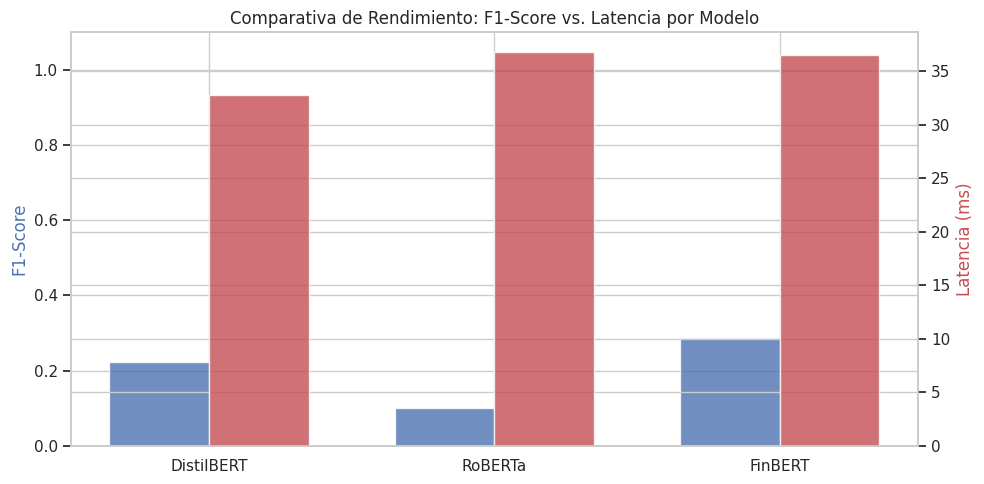

>> Proceso de evaluación y prototipado finalizado con éxito.


In [7]:
# ==============================================================================
# BLOQUE 8: VISUALIZACIÓN Y RESUMEN FINAL
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética de gráficas
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(10, 5))

# Gráfica de F1-Score vs Latencia
models_list = df_metrics["Modelo"]
f1_scores = df_metrics["F1-Score (Weighted)"]
latencies = df_metrics["Latencia Media (ms)"]

x = np.arange(len(models_list))
width = 0.35

ax1.bar(x - width/2, f1_scores, width, label='F1-Score (Mayor es mejor)', color='b', alpha=0.8)
ax1.set_ylabel('F1-Score', color='b')
ax1.set_ylim(0, 1.1)

ax2 = ax1.twinx()
ax2.bar(x + width/2, latencies, width, label='Latencia Media ms (Menor es mejor)', color='r', alpha=0.8)
ax2.set_ylabel('Latencia (ms)', color='r')

plt.xticks(x, models_list)
plt.title("Comparativa de Rendimiento: F1-Score vs. Latencia por Modelo")
fig.tight_layout()
plt.show()

print(">> Proceso de evaluación y prototipado finalizado con éxito.")